<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu
Mounted at /content/drive
Rows: 332 | Train: 215 | Validation: 50 | Test: 67
Class counts (train): {0: 123, 1: 92}
Class counts (validation): {0: 29, 1: 21}
Class counts (test): {0: 39, 1: 28}
Automatic class weights: [0.87398374 1.16847826]
Epoch 001 | train loss=0.7056 | val loss=0.7030
Epoch 025 | train loss=0.4933 | val loss=0.5889
Epoch 050 | train loss=0.4265 | val loss=0.6182
Early stopping at epoch 69.


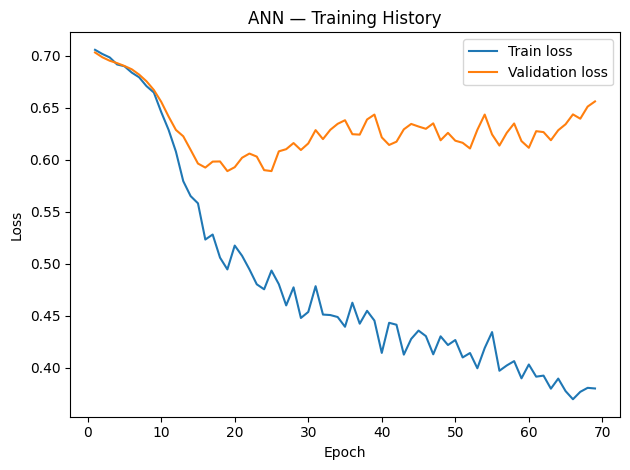

Validation balanced accuracy: 0.7430
Selected threshold: 0.360

TEST METRICS
 Accuracy                0.701493
Balanced_Accuracy       0.713370
Precision               0.611111
Recall                  0.785714
F1                      0.687500
ROC_AUC                 0.787546
PR_AUC                  0.764680
Threshold               0.360000
Best_Validation_Loss    0.588929
dtype: float64

Confusion matrix:
 [[25 14]
 [ 6 22]]

Classification report:
               precision    recall  f1-score   support

           0       0.81      0.64      0.71        39
           1       0.61      0.79      0.69        28

    accuracy                           0.70        67
   macro avg       0.71      0.71      0.70        67
weighted avg       0.72      0.70      0.70        67



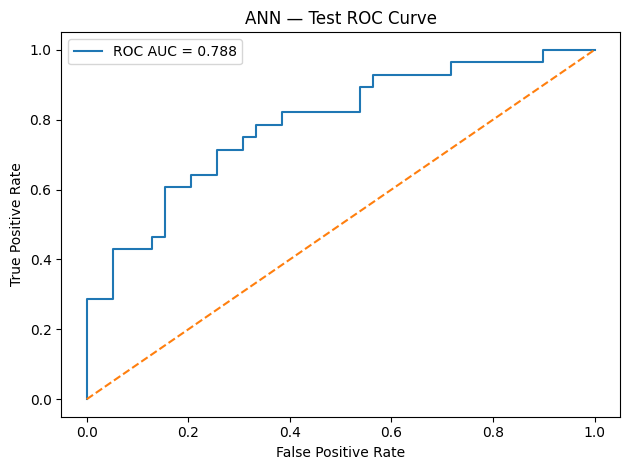

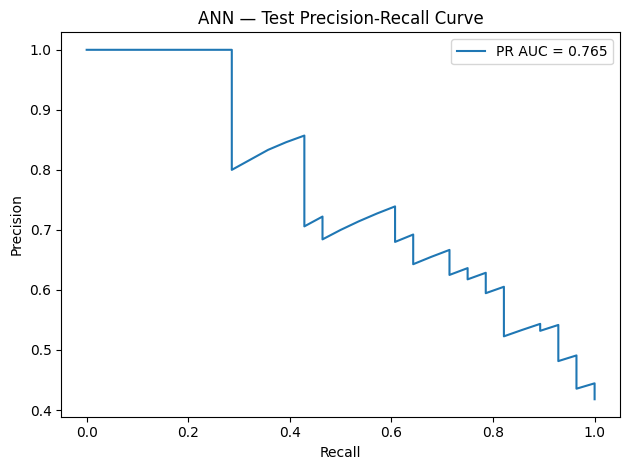

Saved results to: /content/drive/MyDrive/ANN_results


In [1]:

# ============================================================
# ANN — HANCOCK HPV CLASSIFIER
# Shared data preparation | Seed 42 | No SMOTE
# ============================================================

import os, json, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
drive.mount("/content/drive")

# ------------------------------------------------------------
# 1. LOAD AND PREPARE DATA
# ------------------------------------------------------------

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "ANN_results")
os.makedirs(OUT_DIR, exist_ok=True)

def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)
    raise ValueError(f"Cannot read table from {path}")

clinical = load_json_table(os.path.join(BASE, "clinical_data.json"))
pathology = load_json_table(os.path.join(BASE, "pathological_data.json"))
if "patient_id" not in clinical or "patient_id" not in pathology:
    raise KeyError("Both files must contain patient_id.")

df = clinical.merge(pathology, on="patient_id", how="left", suffixes=("", "_path"))
target_candidates = ["hpv_association_p16", "hpv_association_p16_path"]
target_col = next((c for c in target_candidates if c in df.columns), None)
if target_col is None:
    raise KeyError("HPV target column was not found.")

feature_candidates = {
    "age_at_initial_diagnosis": ["age_at_initial_diagnosis"],
    "sex": ["sex"],
    "smoking_status": ["smoking_status"],
    "primary_tumor_site": ["primary_tumor_site"],
    "primarily_metastasis": ["primarily_metastasis"],
    "pN_stage": ["pN_stage", "pN_stage_path", "pathological_N_stage",
                 "pathologic_N_stage", "pathological_n_stage"]
}
rename_map = {}
for name, candidates in feature_candidates.items():
    match = next((c for c in candidates if c in df.columns), None)
    if match is None:
        raise KeyError(f"Missing predictor {name}; checked {candidates}")
    if match != name:
        rename_map[match] = name
df = df.rename(columns=rename_map)
features = list(feature_candidates.keys())

def normalize_label(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    if value in {"negative", "neg", "0", "false", "no"}:
        return 0
    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1
    try:
        number = float(value)
        if number in (0.0, 1.0):
            return int(number)
    except (ValueError, TypeError):
        pass
    return np.nan

df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[["patient_id"] + features + ["HPV_Label"]].copy()

train_val, test = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["HPV_Label"]
)
train, val = train_test_split(
    train_val, test_size=0.1875, random_state=SEED,
    stratify=train_val["HPV_Label"]
)

print("Rows:", len(df), "| Train:", len(train), "| Validation:", len(val), "| Test:", len(test))
print("Class counts (train):", train["HPV_Label"].value_counts().sort_index().to_dict())
print("Class counts (validation):", val["HPV_Label"].value_counts().sort_index().to_dict())
print("Class counts (test):", test["HPV_Label"].value_counts().sort_index().to_dict())

numeric_features = ["age_at_initial_diagnosis"]
categorical_features = [c for c in features if c not in numeric_features]
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder)
    ]), categorical_features)
])

X_train = preprocessor.fit_transform(train[features]).astype(np.float32)
X_val = preprocessor.transform(val[features]).astype(np.float32)
X_test = preprocessor.transform(test[features]).astype(np.float32)
y_train = train["HPV_Label"].to_numpy().astype(np.int64)
y_val = val["HPV_Label"].to_numpy().astype(np.int64)
y_test = test["HPV_Label"].to_numpy().astype(np.int64)

# Inverse-frequency class weights calculated from training labels only.
counts = np.bincount(y_train, minlength=2)
weights = len(y_train) / (2.0 * counts)
class_weights = torch.tensor(weights, dtype=torch.float32, device=device)
print("Automatic class weights:", weights)

train_loader = DataLoader(
    TensorDataset(torch.tensor(X_train), torch.tensor(y_train)),
    batch_size=32, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

# ------------------------------------------------------------
# 2. DEFINE AND TRAIN ANN
# ------------------------------------------------------------

class ANNClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.network(x)

model = ANNClassifier(X_train.shape[1]).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

X_val_t = torch.tensor(X_val, dtype=torch.float32, device=device)
y_val_t = torch.tensor(y_val, dtype=torch.long, device=device)
X_test_t = torch.tensor(X_test, dtype=torch.float32, device=device)

history = []
best_val_loss = float("inf")
best_state = None
patience = 50
epochs_without_improvement = 0
MAX_EPOCHS = 500

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    running_loss = 0.0
    seen = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(yb)
        seen += len(yb)

    train_loss = running_loss / max(seen, 1)
    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(X_val_t), y_val_t).item()

    history.append({
        "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 25 == 0:
        print(f"Epoch {epoch:03d} | train loss={train_loss:.4f} | val loss={val_loss:.4f}")

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch}.")
        break

if best_state is None:
    raise RuntimeError("Training did not produce a valid model checkpoint.")

model.load_state_dict(best_state)
torch.save(best_state, os.path.join(OUT_DIR, "best_ann_model.pt"))
pd.DataFrame(history).to_csv(os.path.join(OUT_DIR, "training_history.csv"), index=False)

plt.figure()
plt.plot([r["epoch"] for r in history], [r["train_loss"] for r in history], label="Train loss")
plt.plot([r["epoch"] for r in history], [r["val_loss"] for r in history], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN — Training History")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "training_history.png"), dpi=150)
plt.show()

# ------------------------------------------------------------
# 3. CHOOSE THRESHOLD ON VALIDATION; TEST ONCE
# ------------------------------------------------------------

model.eval()
with torch.no_grad():
    val_prob = torch.softmax(model(X_val_t), dim=1)[:, 1].cpu().numpy()
    test_prob = torch.softmax(model(X_test_t), dim=1)[:, 1].cpu().numpy()

thresholds = np.linspace(0.10, 0.90, 161)
scores = [
    balanced_accuracy_score(y_val, (val_prob >= t).astype(int))
    for t in thresholds
]
max_score = max(scores)
best_threshold = min(
    (t for t, s in zip(thresholds, scores) if s == max_score),
    key=lambda t: abs(t - 0.5)
)

test_pred = (test_prob >= best_threshold).astype(int)
metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Balanced_Accuracy": balanced_accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, test_prob) if len(np.unique(y_test)) == 2 else np.nan,
    "PR_AUC": average_precision_score(y_test, test_prob),
    "Threshold": float(best_threshold),
    "Best_Validation_Loss": float(best_val_loss)
}

print(f"Validation balanced accuracy: {max_score:.4f}")
print(f"Selected threshold: {best_threshold:.3f}")
print("\nTEST METRICS\n", pd.Series(metrics))
print("\nConfusion matrix:\n", confusion_matrix(y_test, test_pred))
print("\nClassification report:\n",
      classification_report(y_test, test_pred, zero_division=0))

pd.DataFrame([metrics]).to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)
pd.DataFrame({
    "patient_id": test["patient_id"].to_numpy(),
    "y_true": y_test, "probability_positive": test_prob,
    "prediction": test_pred
}).to_csv(os.path.join(OUT_DIR, "test_predictions.csv"), index=False)

with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump({
        "model": "ANN", "seed": SEED, "features": features,
        "target_column": target_col, "threshold": float(best_threshold),
        "class_weights": weights.tolist(), "smote": False,
        "split": {"train": len(train), "validation": len(val), "test": len(test)},
        "epochs_run": len(history), "best_validation_loss": float(best_val_loss)
    }, f, indent=2)

if len(np.unique(y_test)) == 2:
    fpr, tpr, _ = roc_curve(y_test, test_prob)
    plt.figure()
    plt.plot(fpr, tpr, label=f"ROC AUC = {metrics['ROC_AUC']:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ANN — Test ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "roc_curve.png"), dpi=150)
    plt.show()

    precision, recall, _ = precision_recall_curve(y_test, test_prob)
    plt.figure()
    plt.plot(recall, precision, label=f"PR AUC = {metrics['PR_AUC']:.3f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("ANN — Test Precision-Recall Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "pr_curve.png"), dpi=150)
    plt.show()

print("Saved results to:", OUT_DIR)
